# PA-3 — Questions 3 to 7

## Question 3 – Dataset Preparation and Graph Construction

### Q3(a) – Data extraction and resampling

#### Runtime hardware

In [1]:
import os
import glob
import shutil
import subprocess
import psutil

# Hardware of the Colab runtime (needed for Q7)
print("RAM (GB) :", round(psutil.virtual_memory().total / 1e9, 1))
print("CPUs :", os.cpu_count())

# nvidia-smi only exists on GPU runtimes
if shutil.which("nvidia-smi") is None:
    print("GPU : None")
else:
    gpu_info = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"],
        capture_output=True,
        text=True,
    )
    print(gpu_info.stdout)

# TPU chips show up as device files; listing them does not claim the TPU
tpu_files = glob.glob("/dev/accel*") + glob.glob("/dev/vfio/[0-9]*")
print("TPU chips :", len(tpu_files))

RAM (GB) : 50.5
CPUs : 24
GPU : None
TPU chips : 1


#### Kaggle login

In [2]:
from getpass import getpass

# Typed in at run time so the key is never saved in the notebook
os.environ["KAGGLE_USERNAME"] = input("Kaggle username : ")
os.environ["KAGGLE_KEY"] = getpass("Kaggle API key : ")

#### Dataset file list

In [3]:
# List the files in the LargeST dataset before downloading anything
!kaggle datasets files liuxu77/largest

name                      size  creationDate                
------------------  ----------  --------------------------  
ca_his_raw_2017.h5  7233256952  2023-06-13 11:28:22.455000  
ca_his_raw_2018.h5  7233256952  2023-06-13 11:28:20.814000  
ca_his_raw_2019.h5  7233256952  2023-06-13 11:28:18.310000  
ca_his_raw_2020.h5  7253073656  2023-06-13 11:28:14.781000  
ca_his_raw_2021.h5  7233256952  2023-06-13 11:28:06.156000  
ca_meta.csv             570431  2023-06-13 11:25:29.591000  
ca_rn_adj.npy        591680128  2023-06-13 11:25:38.802000  


#### Download files

In [4]:
data_dir = "/content/largest"
os.makedirs(data_dir, exist_ok=True)

free_gb = shutil.disk_usage(data_dir).free / 1e9
print("Free disk (GB) :", round(free_gb, 1))

files_needed = [
    "ca_meta.csv",
    "ca_rn_adj.npy",
    "ca_his_raw_2020.h5",
    "ca_his_raw_2021.h5",
]


def download_file(file_name):
    if os.path.exists(os.path.join(data_dir, file_name)):
        print("Already downloaded :", file_name)
        return

    print("Downloading :", file_name)
    command = ["kaggle", "datasets", "download", "liuxu77/largest"]
    command += ["-f", file_name, "-p", data_dir]
    result = subprocess.run(command, capture_output=True, text=True)
    print(result.stdout, result.stderr)

    # Kaggle sometimes sends large files as a zip
    zip_path = os.path.join(data_dir, file_name + ".zip")
    if os.path.exists(zip_path):
        subprocess.run(["unzip", "-q", "-o", zip_path, "-d", data_dir], check=True)
        os.remove(zip_path)


for file_name in files_needed:
    download_file(file_name)

for file_name in files_needed:
    size_gb = os.path.getsize(os.path.join(data_dir, file_name)) / 1e9
    print(file_name, ":", round(size_gb, 2), "GB")

Free disk (GB) : 241.9
Dataset URL: https://www.kaggle.com/datasets/liuxu77/largest
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)

 
  0%|          | 0.00/557k [00:00<?, ?B/s]
100%|██████████| 557k/557k [00:00<00:00, 2.15MB/s]
100%|██████████| 557k/557k [00:00<00:00, 2.15MB/s]

Dataset URL: https://www.kaggle.com/datasets/liuxu77/largest
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)

 
  0%|          | 0.00/2.32M [00:00<?, ?B/s]
100%|██████████| 2.32M/2.32M [00:00<00:00, 322MB/s]

Dataset URL: https://www.kaggle.com/datasets/liuxu77/largest
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)

 
  0%|          | 0.00/1.39G [00:00<?, ?B/s]
  0%|          | 7.00M/1.39G [00:00<00:29, 50.1MB/s]
  1%|          | 16.0M/1.39G [00:00<00:20, 71.9MB/s]
  3%|▎         | 43.0M/1.39G [00:00<00:10, 142MB/s] 
  5%|▍         | 68.0M/1.39G [00:00<00:07, 182MB/s]
  6%|▌         | 86.0M/1.39G [00:00<00:08, 169MB/s]
  7%|▋         | 103M/

#### Check files open

In [5]:
import numpy as np
import pandas as pd
import h5py

# Sensor metadata
meta = pd.read_csv(os.path.join(data_dir, "ca_meta.csv"))
print("Meta shape :", meta.shape)
print("Meta columns :", list(meta.columns))
print(meta.head())
print("San Diego sensors :", (meta["County"] == "San Diego").sum())

# Adjacency, memory-mapped so it is not fully loaded yet
adj = np.load(os.path.join(data_dir, "ca_rn_adj.npy"), mmap_mode="r")
print("Adjacency shape :", adj.shape)
print("Adjacency dtype :", adj.dtype)
print(adj[:5, :5])


def print_h5_item(name, item):
    # Only prints the layout; no values are read
    if isinstance(item, h5py.Dataset):
        print(" ", name, "shape :", item.shape, "dtype :", item.dtype)


for year in [2020, 2021]:
    file_name = "ca_his_raw_" + str(year) + ".h5"
    print("Layout of", file_name)
    with h5py.File(os.path.join(data_dir, file_name), "r") as h5_file:
        h5_file.visititems(print_h5_item)

Meta shape : (8600, 10)
Meta columns : ['ID', 'Lat', 'Lng', 'District', 'County', 'Fwy', 'Lanes', 'Type', 'Direction', 'ID2']
       ID        Lat         Lng  District      County   Fwy  Lanes      Type  \
0  317802  38.389811 -121.479587         3  Sacramento  I5-N      2  Mainline   
1  312134  38.412564 -121.484319         3  Sacramento  I5-N      2  Mainline   
2  312133  38.428630 -121.487657         3  Sacramento  I5-N      3  Mainline   
3  313159  38.450246 -121.492176         3  Sacramento  I5-N      3  Mainline   
4  319767  38.465539 -121.496450         3  Sacramento  I5-N      3  Mainline   

  Direction  ID2  
0         N    0  
1         N    1  
2         N    2  
3         N    3  
4         N    4  
San Diego sensors : 716
Adjacency shape : (8600, 8600)
Adjacency dtype : float64
[[1.         0.71927804 0.         0.         0.        ]
 [0.         1.         0.84842556 0.         0.        ]
 [0.         0.         1.         0.74261522 0.        ]
 [0.         0.   

#### Sensor order and time range

In [6]:
# San Diego rows in the metadata, kept in metadata order
sd_meta = meta[meta["County"] == "San Diego"]
sd_positions = sd_meta["ID2"].to_numpy()
all_ids = meta["ID"].astype(str).to_numpy()

print("Sensor IDs are unique :", meta["ID"].is_unique)
print("ID2 equals row number :", np.array_equal(meta["ID2"], np.arange(len(meta))))
print("San Diego sensors :", len(sd_positions))
print("First and last position :", sd_positions[0], sd_positions[-1])

block_size = sd_positions[-1] - sd_positions[0] + 1
print("Positions are one block :", block_size == len(sd_positions))


def check_h5_file(year):
    file_name = "ca_his_raw_" + str(year) + ".h5"
    with h5py.File(os.path.join(data_dir, file_name), "r") as h5_file:
        column_ids = h5_file["t/axis0"][:].astype(str)
        block_ids = h5_file["t/block0_items"][:].astype(str)
        times = pd.to_datetime(h5_file["t/axis1"][:])

    columns_match = np.array_equal(column_ids, all_ids)
    block_match = np.array_equal(block_ids, all_ids)
    steps = np.unique(np.diff(times))

    print(year, "column IDs match metadata order :", columns_match)
    print(year, "value block uses the same order :", block_match)
    print(year, "first timestamp :", times[0])
    print(year, "last timestamp :", times[-1])
    print(year, "time steps found :", steps)


check_h5_file(2020)
check_h5_file(2021)

Sensor IDs are unique : True
ID2 equals row number : True
San Diego sensors : 716
First and last position : 6931 7646
Positions are one block : True
2020 column IDs match metadata order : True
2020 value block uses the same order : True
2020 first timestamp : 2020-01-01 00:00:00
2020 last timestamp : 2020-12-31 23:55:00
2020 time steps found : [300000000000]
2021 column IDs match metadata order : True
2021 value block uses the same order : True
2021 first timestamp : 2021-01-01 00:00:00
2021 last timestamp : 2021-12-31 23:55:00
2021 time steps found : [300000000000]


#### Load San Diego flow (5-minute)

In [7]:
import time

# San Diego sensors are one block of columns, so a slice selects all 716
sd_start = sd_positions[0]
sd_end = sd_positions[-1] + 1
sd_ids = all_ids[sd_start:sd_end]


def load_sd_year(year):
    file_name = "ca_his_raw_" + str(year) + ".h5"
    with h5py.File(os.path.join(data_dir, file_name), "r") as h5_file:
        times = pd.to_datetime(h5_file["t/axis1"][:])
        # Reads only the San Diego columns, not all 8600
        values = h5_file["t/block0_values"][:, sd_start:sd_end]
    return pd.DataFrame(values, index=times, columns=sd_ids)


start_time = time.time()
flow_5min = pd.concat([load_sd_year(2020), load_sd_year(2021)])
print("Load time (s) :", round(time.time() - start_time, 1))

ids_match = np.array_equal(flow_5min.columns, sd_meta["ID"].astype(str))
memory_gb = flow_5min.memory_usage().sum() / 1e9

print("Shape :", flow_5min.shape)
print("Memory (GB) :", round(memory_gb, 2))
print("Columns match San Diego IDs :", ids_match)
print("Index is sorted :", flow_5min.index.is_monotonic_increasing)
print("Duplicate timestamps :", flow_5min.index.duplicated().sum())
print("Min value :", np.nanmin(flow_5min.values))
print("Max value :", np.nanmax(flow_5min.values))
print(flow_5min.iloc[:5, :5])

Load time (s) : 1.4
Shape : (210528, 716)
Memory (GB) : 1.21
Columns match San Diego IDs : True
Index is sorted : True
Duplicate timestamps : 0
Min value : 0.0
Max value : 999.0
                     1114091  1118333  1118348  1114720  1118352
2020-01-01 00:00:00     78.0     49.0     42.0     47.0     42.0
2020-01-01 00:05:00     47.0     21.0     19.0     28.0     29.0
2020-01-01 00:10:00     43.0     24.0     22.0     37.0     25.0
2020-01-01 00:15:00     53.0     26.0     22.0     40.0     48.0
2020-01-01 00:20:00     68.0     30.0     22.0     39.0     34.0


#### Overall missing and suspicious values

In [8]:
is_nan = flow_5min.isna()
is_zero = flow_5min == 0
is_999 = flow_5min == 999

print("Total values :", flow_5min.size)
print("NaN values :", is_nan.values.sum())
print("NaN % :", round(100 * is_nan.values.mean(), 2))
print("Zero % :", round(100 * is_zero.values.mean(), 2))
print("Sensors fully missing :", is_nan.all().sum())
print("Sensors with no missing values :", (~is_nan.any()).sum())
print("Timestamps with every sensor missing :", is_nan.all(axis=1).sum())

# Is 999 a cap? Look at how often it and other high values appear
high_values = flow_5min.values[flow_5min.values >= 500]
print("Values equal to 999 :", is_999.values.sum())
print("Values 900 or more :", (high_values >= 900).sum())
print("Values 500 or more :", len(high_values))
print("Highest distinct values :", np.unique(high_values)[-10:])

Total values : 150738048
NaN values : 7636666
NaN % : 5.07
Zero % : 0.27
Sensors fully missing : 19
Sensors with no missing values : 0
Timestamps with every sensor missing : 24
Values equal to 999 : 155
Values 900 or more : 33148
Values 500 or more : 10082873
Highest distinct values : [990. 991. 992. 993. 994. 995. 996. 997. 998. 999.]


#### Per-sensor summary

In [9]:
from IPython.display import display


def longest_run(is_true):
    # Length of the longest stretch of consecutive True values
    padded = np.concatenate([[0], is_true.to_numpy().astype(int), [0]])
    edges = np.flatnonzero(np.diff(padded))
    if len(edges) == 0:
        return 0
    return (edges[1::2] - edges[0::2]).max()


# 12 five-minute steps per hour
sensor_summary = pd.DataFrame(
    {
        "nan_pct": 100 * is_nan.mean(),
        "zero_pct": 100 * is_zero.mean(),
        "longest_nan_hours": is_nan.apply(longest_run) / 12,
        "longest_zero_hours": is_zero.apply(longest_run) / 12,
        "count_999": is_999.sum(),
    }
)
sensor_info = sd_meta.set_index(sd_meta["ID"].astype(str))[["Fwy", "Lanes", "Type"]]
sensor_summary = sensor_info.join(sensor_summary).round(2)

print("Spread across the 716 sensors")
display(sensor_summary.describe().round(2))

print("Sensors with the most missing values")
display(sensor_summary.sort_values("nan_pct", ascending=False).head(15))

print("Sensors that report 999")
has_999 = sensor_summary[sensor_summary["count_999"] > 0]
display(has_999.sort_values("count_999", ascending=False))

Spread across the 716 sensors


,Lanes,nan_pct,zero_pct,longest_nan_hours,longest_zero_hours,count_999
count,716.00,716.00,716.00,716.0,716.00,716.00
mean,3.97,5.06,0.27,883.5,1.77,0.22
std,1.08,20.26,1.80,3553.7,5.70,2.59
min,2.00,0.01,0.00,1.0,0.00,0.00
25%,3.00,0.01,0.00,1.0,0.08,0.00
50%,4.00,0.01,0.01,1.0,0.17,0.00
75%,5.00,0.01,0.05,1.0,0.67,0.00
max,8.00,100.00,30.92,17544.0,58.83,59.00


Sensors with the most missing values


,Fwy,Lanes,Type,nan_pct,zero_pct,longest_nan_hours,longest_zero_hours,count_999
ID,,,,,,,,
1123087,I5-N,4,Mainline,100.0,0.0,17544.0,0.0,0
1123072,I805-S,2,Mainline,100.0,0.0,17544.0,0.0,0
1123064,I805-S,3,Mainline,100.0,0.0,17544.0,0.0,0
1123069,I805-S,3,Mainline,100.0,0.0,17544.0,0.0,0
1118442,I5-S,4,Mainline,100.0,0.0,17544.0,0.0,0
1122601,I5-S,5,Mainline,100.0,0.0,17544.0,0.0,0
1108323,SR125-S,3,Mainline,100.0,0.0,17544.0,0.0,0
1115348,I5-S,4,Mainline,100.0,0.0,17544.0,0.0,0
1108299,SR125-N,3,Mainline,100.0,0.0,17544.0,0.0,0


Sensors that report 999


,Fwy,Lanes,Type,nan_pct,zero_pct,longest_nan_hours,longest_zero_hours,count_999
ID,,,,,,,,
1117931,I15-S,6,Mainline,14.47,0.00,16.92,0.42,59
1117748,I5-N,6,Mainline,0.34,0.00,1.67,0.08,22
1119909,I5-S,4,Mainline,0.11,0.00,1.00,0.08,19
1108725,I5-S,4,Mainline,0.20,0.20,1.00,19.08,15
1120611,I15-N,8,Mainline,0.16,0.09,1.00,0.17,12
1115838,I15-S,6,Mainline,0.10,0.00,1.00,0.08,8
1115463,I8-E,6,Mainline,0.84,0.00,1.00,0.08,6
1122479,I15-S,7,Mainline,0.36,0.21,1.67,35.25,6
1108448,I805-N,5,Mainline,0.02,0.01,1.00,0.25,2


#### Missing values per month

In [10]:
month_summary = pd.DataFrame(
    {
        "nan_pct": 100 * is_nan.mean(axis=1).resample("MS").mean(),
        "zero_pct": 100 * is_zero.mean(axis=1).resample("MS").mean(),
    }
)
month_summary.index = month_summary.index.strftime("%Y-%m")
month_summary.round(2)

,nan_pct,zero_pct
2020-01,2.81,0.19
2020-02,2.82,0.22
2020-03,3.16,0.29
2020-04,3.81,0.41
2020-05,3.80,0.35
2020-06,3.65,0.26
2020-07,3.66,0.28
2020-08,3.67,0.23
2020-09,3.67,0.27
2020-10,6.03,0.28


#### Resample to 15 minutes

In [11]:
# Flow is a vehicle count per 5 minutes, so the three counts are summed.
# min_count=3 keeps a window as NaN if any of its three values is missing.
flow_15min = flow_5min.resample("15min").sum(min_count=3)

first_window = flow_5min.iloc[0:3, 0].sum()
print("Shape :", flow_15min.shape)
print("Expected rows :", (366 + 365) * 96)
print("First timestamp :", flow_15min.index[0])
print("Last timestamp :", flow_15min.index[-1])
print("First window equals sum of 3 values :", flow_15min.iloc[0, 0] == first_window)
print("NaN % after resampling :", round(100 * flow_15min.isna().values.mean(), 2))

Shape : (70176, 716)
Expected rows : 70176
First timestamp : 2020-01-01 00:00:00
Last timestamp : 2021-12-31 23:45:00
First window equals sum of 3 values : True
NaN % after resampling : 5.08


#### Handle missing values

In [12]:
# True where a real reading exists; used later so filled values are not scored
observed_mask = flow_15min.notna()

# Forward fill uses past values only; backward fill covers gaps at the start.
# Sensors that never report have nothing to copy, so they are set to 0.
flow_filled = flow_15min.ffill().bfill().fillna(0)

print("Sensors never observed :", (~observed_mask).all().sum())
print("Filled values :", (~observed_mask).values.sum())
print("Observed % :", round(100 * observed_mask.values.mean(), 2))
print("NaN left after filling :", flow_filled.isna().values.sum())

Sensors never observed : 19
Filled values : 2550289
Observed % : 94.92
NaN left after filling : 0


#### Plot three sensors over one week

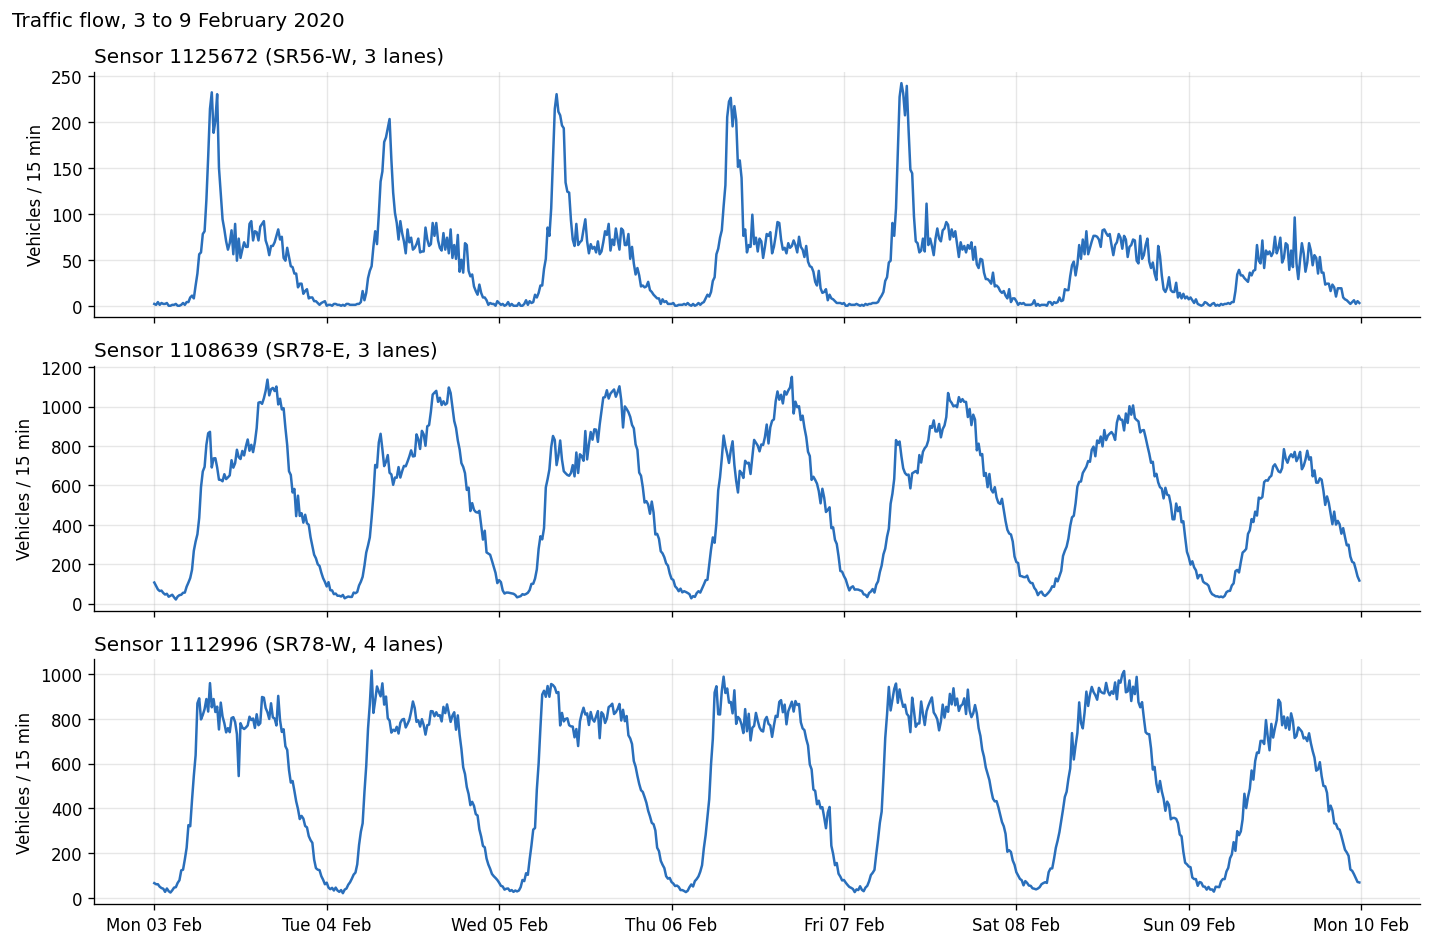

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# One full Monday-to-Sunday week from the training year
week = flow_15min.loc["2020-02-03":"2020-02-09"]

# Three well-observed sensors, each on a different freeway
chosen = sensor_summary.sort_values("nan_pct").drop_duplicates("Fwy").head(3)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, dpi=120)

for ax, sensor_id in zip(axes, chosen.index):
    fwy = chosen.loc[sensor_id, "Fwy"]
    lanes = chosen.loc[sensor_id, "Lanes"]
    title = "Sensor " + sensor_id + " (" + fwy + ", " + str(lanes) + " lanes)"

    ax.plot(week.index, week[sensor_id], color="#2a6fbb", linewidth=1.5)
    ax.set_title(title, loc="left")
    ax.set_ylabel("Vehicles / 15 min")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
fig.suptitle("Traffic flow, 3 to 9 February 2020", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### Q3(b) – Constructing the traffic graph

#### Extract San Diego adjacency, edges and symmetry

In [14]:
# Same positions as the flow columns, so row i of the adjacency is column i of the flow
adj_sd = np.array(adj[sd_start:sd_end, sd_start:sd_end])
order_match = np.array_equal(all_ids[sd_start:sd_end], flow_15min.columns)

# Diagonal holds self-loops, so edges are counted without it
off_diagonal = adj_sd.copy()
np.fill_diagonal(off_diagonal, 0)
edge_weights = off_diagonal[off_diagonal > 0]

# Edges whose reverse direction is missing
one_way_edges = np.count_nonzero((off_diagonal > 0) & (off_diagonal.T == 0))

print("Adjacency shape :", adj_sd.shape)
print("Order matches flow columns :", order_match)
print("Nodes :", adj_sd.shape[0])
print("Nonzero entries with diagonal :", np.count_nonzero(adj_sd))
print("Nonzero edges without diagonal :", len(edge_weights))
print("Diagonal values :", np.unique(np.diag(adj_sd)))
print("Is symmetric :", np.allclose(adj_sd, adj_sd.T))
print("Edges with no reverse edge :", one_way_edges)
print("Smallest edge weight :", edge_weights.min())
print("Largest edge weight :", edge_weights.max())

Adjacency shape : (716, 716)
Order matches flow columns : True
Nodes : 716
Nonzero entries with diagonal : 18035
Nonzero edges without diagonal : 17319
Diagonal values : [1.]
Is symmetric : False
Edges with no reverse edge : 3711
Smallest edge weight : 0.010001835317713963
Largest edge weight : 0.9999998696620915


#### Adjacency heatmap

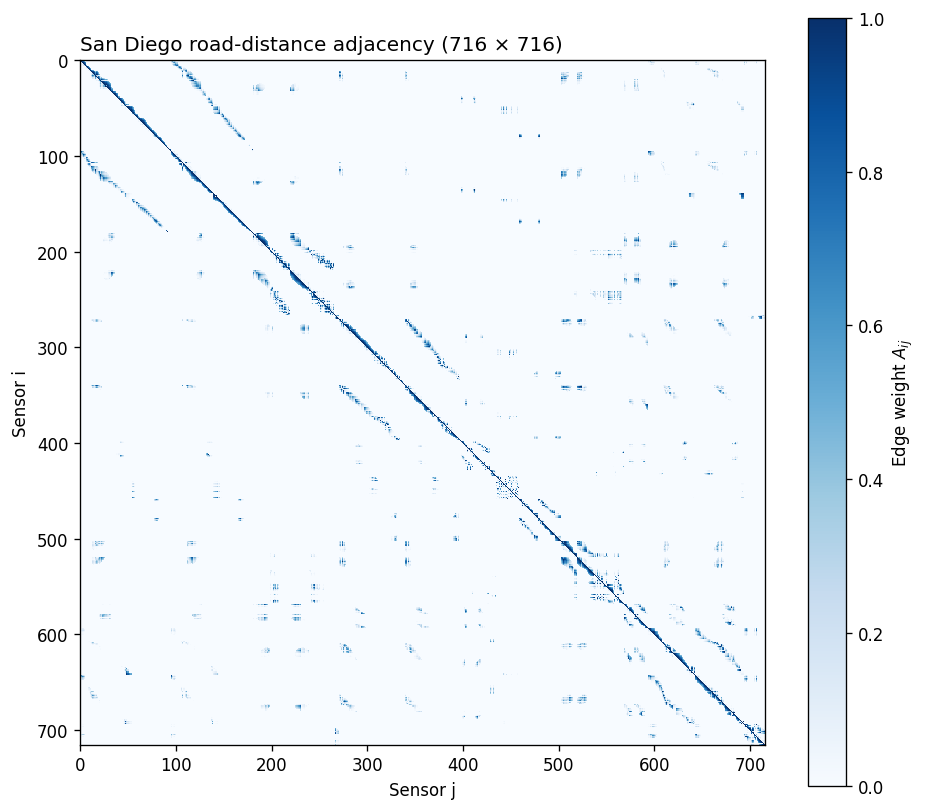

In [15]:
fig, ax = plt.subplots(figsize=(8, 7), dpi=120)

image = ax.imshow(adj_sd, cmap="Blues", interpolation="nearest")
fig.colorbar(image, ax=ax, label="Edge weight $A_{ij}$")

ax.set_title("San Diego road-distance adjacency (716 × 716)", loc="left")
ax.set_xlabel("Sensor j")
ax.set_ylabel("Sensor i")
fig.tight_layout()
plt.show()

#### Neighbours per sensor

Fewest neighbours : 0
Most neighbours : 70
Mean neighbours : 24.19
Median neighbours : 20.0
Sensors with no neighbours : 8


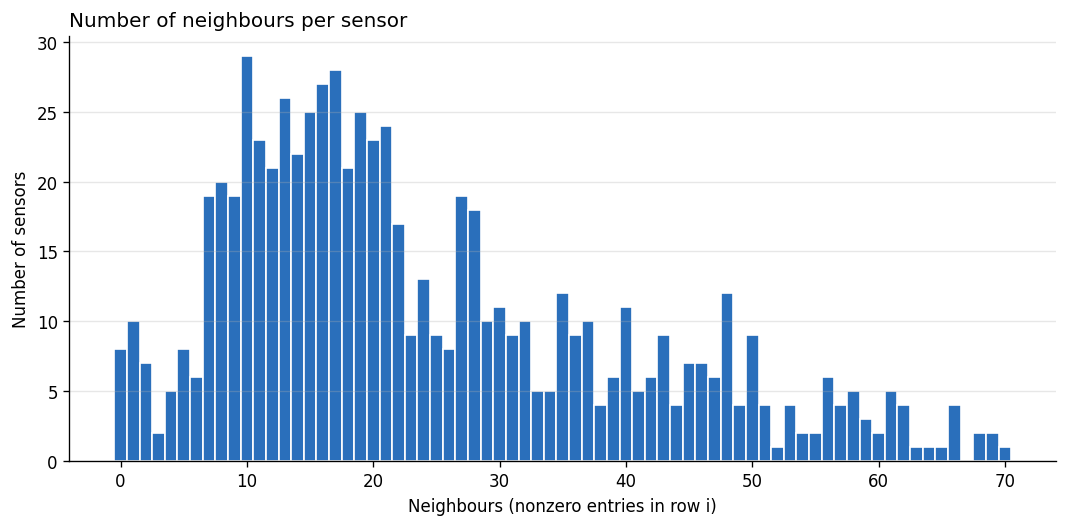

In [16]:
# Neighbours of sensor i are the nonzero entries in row i, not counting itself
neighbour_counts = np.count_nonzero(off_diagonal, axis=1)

print("Fewest neighbours :", neighbour_counts.min())
print("Most neighbours :", neighbour_counts.max())
print("Mean neighbours :", round(neighbour_counts.mean(), 2))
print("Median neighbours :", np.median(neighbour_counts))
print("Sensors with no neighbours :", np.sum(neighbour_counts == 0))

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
bins = np.arange(neighbour_counts.max() + 2) - 0.5
ax.hist(neighbour_counts, bins=bins, color="#2a6fbb", edgecolor="white")

ax.set_title("Number of neighbours per sensor", loc="left")
ax.set_xlabel("Neighbours (nonzero entries in row i)")
ax.set_ylabel("Number of sensors")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

#### What a nonzero $A_{ij}$ means

Sensor $j$ is within a short driving distance of sensor $i$ on the road network; the closer they are, the larger the weight. Distance is measured in the driving direction, so $A_{ij}$ and $A_{ji}$ can differ.

### Q3(c) – Understanding graph neighbourhoods

#### One-hop and two-hop neighbours of one sensor

In [17]:
# Sensor from the week plot
sensor_id = "1108639"
sensor_index = list(flow_15min.columns).index(sensor_id)
sd_info = sd_meta.set_index(sd_meta["ID"].astype(str))

# Edges without self-loops, as 0/1
has_edge = (off_diagonal > 0).astype(int)

# One hop: nonzero entries in the sensor's row
one_hop = np.flatnonzero(has_edge[sensor_index])

# Two hops: reachable through paths with at most two edges
paths_of_two = has_edge[sensor_index] @ has_edge
within_two = (has_edge[sensor_index] + paths_of_two) > 0
within_two[sensor_index] = False
two_hop = np.flatnonzero(within_two)

print("Sensor :", sensor_id, "on", sd_info.loc[sensor_id, "Fwy"])
print("One-hop neighbours :", len(one_hop))
print("Two-hop neighbours (within two edges) :", len(two_hop))
print("Reached only at the second hop :", len(two_hop) - len(one_hop))

neighbours = pd.DataFrame(
    {
        "ID": flow_15min.columns[two_hop],
        "hop": np.where(np.isin(two_hop, one_hop), 1, 2),
        "weight": adj_sd[sensor_index, two_hop].round(3),
    }
)
neighbours["Fwy"] = sd_info.loc[neighbours["ID"], "Fwy"].to_numpy()

print("Neighbours per freeway at each hop")
display(pd.crosstab(neighbours["Fwy"], neighbours["hop"]))

print("One-hop neighbours")
one_hop_table = neighbours[neighbours["hop"] == 1]
display(one_hop_table.sort_values("weight", ascending=False))

Sensor : 1108639 on SR78-E
One-hop neighbours : 8
Two-hop neighbours (within two edges) : 28
Reached only at the second hop : 20
Neighbours per freeway at each hop


hop,1,2
Fwy,,
I5-N,1,6
I5-S,0,7
SR78-E,2,4
SR78-W,5,3


One-hop neighbours


,ID,hop,weight,Fwy
23,1116318,1,0.708,SR78-W
17,1108637,1,0.597,SR78-E
24,1108401,1,0.543,SR78-W
16,1116167,1,0.171,SR78-E
25,1108760,1,0.132,SR78-W
22,1108621,1,0.121,SR78-W
20,1112996,1,0.039,SR78-W
3,1115289,1,0.018,I5-N


#### Discussion

**Why might neighbouring sensors help?** Vehicles passing an upstream sensor reach sensor 1108639 minutes later, and congestion further along the road backs up into it, so neighbours give an early signal of what is coming. Nearby sensors also share the same demand, and their readings can cover gaps in the sensor's own data. Not every neighbour is equally useful: 5 of its 8 one-hop neighbours are on SR78-W, the opposite direction, which peaks in the morning while SR78-E peaks in the evening (week plot).

**One-hop vs two-hop aggregation.** One graph convolution layer combines the sensor with its 8 direct neighbours, almost all on SR78. A second layer repeats this on already-mixed features, so information arrives from 28 sensors, including 13 on I-5 with no direct edge. Two hops give a wider view, but each far sensor's signal is weaker because it is averaged twice.

**Could too many layers hurt?** Yes. Each layer averages over neighbours, so after many layers the features of nearby sensors become almost the same (over-smoothing) and the model can no longer tell them apart. The neighbourhood also grows quickly (8 to 28 sensors after two hops here), so signals from many distant sensors are squeezed into one small vector, even though traffic far away has little effect within a 1-hour horizon. Extra layers also add parameters and training time.

## Question 4 – Spatio-Temporal Traffic Forecasting

### Q4(a) – Preparing forecasting windows

#### Chronological splits

In [18]:
splits = {
    "train": ("2020-01-01", "2020-12-31"),
    "val": ("2021-01-01", "2021-03-31"),
    "test": ("2021-04-01", "2021-12-31"),
}

split_flow = {}
split_mask = {}
for name, (start, end) in splits.items():
    split_flow[name] = flow_filled.loc[start:end].to_numpy(dtype=np.float32)
    split_mask[name] = observed_mask.loc[start:end].to_numpy()
    print(name, "steps :", len(split_flow[name]), "from", start, "to", end)

# A sensor that first reports in 2021 would have its 2020 gap back-filled
# with 2021 values, which would leak later data into training
first_reading = observed_mask.idxmax()[observed_mask.any()]
print("Sensors whose first reading is in 2021 :", (first_reading.dt.year == 2021).sum())

train steps : 35136 from 2020-01-01 to 2020-12-31
val steps : 8640 from 2021-01-01 to 2021-03-31
test steps : 26400 from 2021-04-01 to 2021-12-31
Sensors whose first reading is in 2021 : 0


#### Normalise with training statistics

In [19]:
# Mean and std from observed training values only (filled values left out)
train_values = split_flow["train"][split_mask["train"]]
flow_mean = train_values.mean()
flow_std = train_values.std()

print("Training mean (vehicles / 15 min) :", round(float(flow_mean), 2))
print("Training std (vehicles / 15 min) :", round(float(flow_std), 2))

split_scaled = {}
for name in splits:
    split_scaled[name] = (split_flow[name] - flow_mean) / flow_std

# Observed training values should now have mean 0 and std 1
scaled_train = split_scaled["train"][split_mask["train"]]
print("Scaled training mean :", round(float(scaled_train.mean()), 3))
print("Scaled training std :", round(float(scaled_train.std()), 3))

Training mean (vehicles / 15 min) : 607.17
Training std (vehicles / 15 min) : 483.35
Scaled training mean : 0.0
Scaled training std : 1.0


#### Forecasting windows

In [20]:
from numpy.lib.stride_tricks import sliding_window_view

input_steps = 8
output_steps = 4
window_steps = input_steps + output_steps


def make_windows(scaled, mask):
    # Windows are cut inside one split, so none crosses a split boundary.
    # sliding_window_view puts the window last: (samples, sensors, 12)
    values = sliding_window_view(scaled, window_steps, axis=0)
    observed = sliding_window_view(mask, window_steps, axis=0)

    # Reorder to (samples, time, sensors, features) as in the PDF
    x = values[:, :, :input_steps].transpose(0, 2, 1)[..., None]
    y = values[:, :, input_steps:].transpose(0, 2, 1)[..., None]
    y_observed = observed[:, :, input_steps:].transpose(0, 2, 1)[..., None]
    return x, y, y_observed


windows = {}
for name in splits:
    windows[name] = make_windows(split_scaled[name], split_mask[name])
    x, y, y_observed = windows[name]
    print(name, "X :", x.shape, "Y :", y.shape)
    print(name, "observed targets % :", round(100 * y_observed.mean(), 2))

# First training window: inputs are steps 0-7, targets are steps 8-11
x, y, y_observed = windows["train"]
inputs_match = np.array_equal(x[0, :, 0, 0], split_scaled["train"][0:8, 0])
targets_match = np.array_equal(y[0, :, 0, 0], split_scaled["train"][8:12, 0])
print("First window inputs are steps 0-7 :", inputs_match)
print("First window targets are steps 8-11 :", targets_match)

train X : (35125, 8, 716, 1) Y : (35125, 4, 716, 1)
train observed targets % : 95.89
val X : (8629, 8, 716, 1) Y : (8629, 4, 716, 1)
val observed targets % : 93.91
test X : (26389, 8, 716, 1) Y : (26389, 4, 716, 1)
test observed targets % : 93.97
First window inputs are steps 0-7 : True
First window targets are steps 8-11 : True


### Q4(b) – Implementing the forecasting architecture

#### PyTorch TPU setup and normalised adjacency

In [21]:
import sys
import matplotlib
import torch
import torch.nn as nn
from importlib.metadata import version

# Fixed seed for reproducibility; weights are created on the CPU, then moved
seed = 0
np.random.seed(seed)
torch.manual_seed(seed)

# Colab's TPU runtime comes with torch-tpu, which adds a "tpu" device to PyTorch
device = torch.device("tpu")
print("Device :", torch.ones(1).to(device).device)

# Package versions, used to pin requirements.txt
print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("torch-tpu :", version("torch-tpu"))
print("libtpu :", version("libtpu"))
print("NumPy :", np.__version__)
print("pandas :", pd.__version__)
print("h5py :", h5py.__version__)
print("matplotlib :", matplotlib.__version__)
print("psutil :", psutil.__version__)

# The graph is directed, so A is row-normalised: A_hat = D^-1 A.
# Self-loops are already on the diagonal, so I is not added again.
row_sums = adj_sd.sum(axis=1, keepdims=True)
adj_norm = adj_sd / row_sums
adj_norm_t = torch.tensor(adj_norm, dtype=torch.float32).to(device)

print("Smallest row sum before normalising :", row_sums.min())
print("Rows sum to 1 after normalising :", np.allclose(adj_norm.sum(axis=1), 1))

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


Device : tpu:0
Python : 3.13.18
PyTorch : 2.14.1+cpu
torch-tpu : 0.2.0
libtpu : 0.0.50
NumPy : 2.4.6
pandas : 2.2.3
h5py : 3.14.0
matplotlib : 3.10.0
psutil : 5.9.5
Smallest row sum before normalising : 1.0
Rows sum to 1 after normalising : True


#### Model

In [37]:
class TemporalEncoder(nn.Module):
    # Two 1D convolutions over each sensor's input steps, then a linear layer
    def __init__(self, hidden):
        super().__init__()
        self.conv1 = nn.Conv1d(1, hidden, kernel_size=3)
        self.conv2 = nn.Conv1d(hidden, hidden, kernel_size=3)
        # Each kernel-3 convolution shortens the sequence by 2 steps
        self.linear = nn.Linear(hidden * (input_steps - 4), hidden)

    def forward(self, x):
        # (batch, steps, sensors, 1) -> one sequence per sensor
        batch, steps, sensors, _ = x.shape
        x = x.permute(0, 2, 3, 1).reshape(batch * sensors, 1, steps)
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        z = self.linear(x.flatten(1))
        return z.reshape(batch, sensors, -1)


class GraphConv(nn.Module):
    # H = ReLU(A_hat Z W_g), applied to every batch item
    def __init__(self, hidden):
        super().__init__()
        self.weight = nn.Linear(hidden, hidden, bias=False)

    def forward(self, z, adj):
        mixed = torch.einsum("ij,bjd->bid", adj, z)
        return torch.relu(self.weight(mixed))


class STGNN(nn.Module):
    def __init__(self, hidden, adj):
        super().__init__()
        self.adj = adj
        self.encoder = TemporalEncoder(hidden)
        self.graph = GraphConv(hidden)
        self.head = nn.Linear(hidden, output_steps)

    def forward(self, x):
        z = self.encoder(x)
        h = self.graph(z, self.adj)
        # Residual connection: the head sees the sensor's own features plus the
        # neighbour term, so the graph adds to the temporal features, not replaces them
        y = self.head(z + h)
        # (batch, sensors, 4) -> (batch, 4, sensors, 1)
        return y.permute(0, 2, 1).unsqueeze(-1)


hidden = 32
model = STGNN(hidden, adj_norm_t).to(device)
param_count = sum(p.numel() for p in model.parameters())
print("Hidden size :", hidden)
print("Trainable parameters :", param_count)

x_train, y_train, y_train_observed = windows["train"]
sample = torch.tensor(np.ascontiguousarray(x_train[:2]), device=device)
print("Input batch shape :", tuple(sample.shape))
print("Output batch shape :", tuple(model(sample).shape))

Hidden size : 32
Trainable parameters : 8516
Input batch shape : (2, 8, 716, 1)
Output batch shape : (2, 4, 716, 1)


#### Mount Google Drive for checkpoints

In [38]:
from google.colab import drive

# Checkpoints are kept on Drive so they survive a Colab runtime reset
drive.mount("/content/drive")
checkpoint_dir = "/content/drive/MyDrive/PA-3/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

print("Checkpoint folder :", checkpoint_dir)
print("Saved checkpoints :", sorted(os.listdir(checkpoint_dir)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint folder : /content/drive/MyDrive/PA-3/checkpoints
Saved checkpoints : ['stgnn.pt', 'stgnn_fixed.pt', 'temporal_only.pt']


#### Training and evaluation functions

In [39]:
batch_size = 64
max_epochs = 100
patience = 10
learning_rate = 0.001

# Errors are computed on scaled values; multiplying by the std gives vehicles / 15 min
scale = float(flow_std)


def get_batch(split, indices):
    x, y, y_observed = windows[split]
    x_batch = torch.from_numpy(np.ascontiguousarray(x[indices])).to(device)
    y_batch = torch.from_numpy(np.ascontiguousarray(y[indices])).to(device)
    mask = torch.from_numpy(y_observed[indices].astype(np.float32)).to(device)
    return x_batch, y_batch, mask


def masked_mae(pred, target, mask):
    # Filled targets have mask 0, so they do not count in the loss
    return (torch.abs(pred - target) * mask).sum() / mask.sum()


def evaluate(model, split):
    # MAE and RMSE in vehicles / 15 min over observed targets only
    model.eval()
    sample_count = len(windows[split][0])
    abs_sum = torch.zeros((), device=device)
    square_sum = torch.zeros((), device=device)
    count = torch.zeros((), device=device)

    with torch.no_grad():
        for start in range(0, sample_count, batch_size):
            # The last batch is padded to full size so every batch has one shape;
            # padded samples get mask 0
            indices = np.arange(start, start + batch_size)
            valid = torch.from_numpy((indices < sample_count).astype(np.float32))
            indices = np.minimum(indices, sample_count - 1)

            x_batch, y_batch, mask = get_batch(split, indices)
            mask = mask * valid.to(device).view(-1, 1, 1, 1)
            error = (model(x_batch) - y_batch) * scale

            abs_sum += (error.abs() * mask).sum()
            square_sum += (error**2 * mask).sum()
            count += mask.sum()

    mae = (abs_sum / count).item()
    rmse = torch.sqrt(square_sum / count).item()
    return mae, rmse


def to_cpu(value):
    # Checkpoints are stored with CPU tensors so they load on any runtime
    if isinstance(value, torch.Tensor):
        return value.detach().cpu()
    if isinstance(value, dict):
        return {key: to_cpu(item) for key, item in value.items()}
    if isinstance(value, list):
        return [to_cpu(item) for item in value]
    return value


def save_checkpoint(path, checkpoint):
    # Written to a temporary file first, so a disconnect mid-write
    # cannot leave a broken checkpoint behind
    temp_path = path + ".tmp"
    torch.save(checkpoint, temp_path)
    os.replace(temp_path, path)


def train_model(model, name):
    # Same protocol for every model: Adam, MAE loss, early stopping on val MAE.
    # Progress is saved to Drive after every epoch: an interrupted run resumes
    # from its last epoch, and a finished run is loaded instead of trained again.
    path = os.path.join(checkpoint_dir, name + ".pt")
    rng = np.random.default_rng(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    train_count = len(windows["train"][0])
    # The last partial batch is dropped so every training batch has one shape
    batch_count = train_count // batch_size

    checkpoint = {
        "epoch": 0,
        "best_epoch": 0,
        "best_mae": float("inf"),
        "best_state": None,
        "train_time_s": 0.0,
        "history": [],
        "finished": False,
    }

    if os.path.exists(path):
        checkpoint = torch.load(path)
        if checkpoint["finished"]:
            model.load_state_dict(checkpoint["best_state"])
            print("Loaded finished run from :", path)
            print("Best epoch :", checkpoint["best_epoch"])
            print("Training time (s) :", round(checkpoint["train_time_s"], 1))
            return checkpoint

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        rng.bit_generator.state = checkpoint["rng_state"]
        print("Resuming after epoch :", checkpoint["epoch"])

    for epoch in range(checkpoint["epoch"] + 1, max_epochs + 1):
        epoch_start = time.time()
        model.train()
        order = rng.permutation(train_count)
        loss_sum = torch.zeros((), device=device)

        for batch_number in range(batch_count):
            start = batch_number * batch_size
            end = start + batch_size
            x_batch, y_batch, mask = get_batch("train", order[start:end])

            loss = masked_mae(model(x_batch), y_batch, mask)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            # Kept on the TPU; read once per epoch instead of every step
            loss_sum += loss.detach()

        train_mae = loss_sum.item() / batch_count * scale
        val_mae, val_rmse = evaluate(model, "val")
        epoch_time = time.time() - epoch_start
        print(
            "Epoch",
            epoch,
            "train MAE :",
            round(train_mae, 2),
            "val MAE :",
            round(val_mae, 2),
            "time (s) :",
            round(epoch_time, 1),
        )

        # Training time counts the epochs only, not the checkpoint saving
        checkpoint["train_time_s"] += epoch_time
        checkpoint["history"].append(
            {"epoch": epoch, "train_mae": train_mae, "val_mae": val_mae}
        )
        if val_mae < checkpoint["best_mae"]:
            checkpoint["best_mae"] = val_mae
            checkpoint["best_epoch"] = epoch
            checkpoint["best_state"] = to_cpu(model.state_dict())

        stop_early = epoch - checkpoint["best_epoch"] >= patience
        checkpoint["epoch"] = epoch
        checkpoint["model_state"] = to_cpu(model.state_dict())
        checkpoint["optimizer_state"] = to_cpu(optimizer.state_dict())
        checkpoint["rng_state"] = rng.bit_generator.state
        checkpoint["finished"] = stop_early or epoch == max_epochs
        save_checkpoint(path, checkpoint)

        if stop_early:
            print("Early stopping, no val improvement for", patience, "epochs")
            break

    model.load_state_dict(checkpoint["best_state"])
    print("Best epoch :", checkpoint["best_epoch"])
    print("Training time (s) :", round(checkpoint["train_time_s"], 1))
    return checkpoint

#### Train STGNN

In [41]:
# Same seed before building each model, so every run starts the same way
torch.manual_seed(seed)
stgnn = STGNN(hidden, adj_norm_t).to(device)
# New checkpoint name, so the run without the residual connection is not loaded
run = train_model(stgnn, "stgnn_fixed")

results = {}
val_mae, val_rmse = evaluate(stgnn, "val")
test_mae, test_rmse = evaluate(stgnn, "test")
results["STGNN"] = {
    "val_mae": val_mae,
    "val_rmse": val_rmse,
    "test_mae": test_mae,
    "test_rmse": test_rmse,
    "best_epoch": run["best_epoch"],
    "epochs_run": run["epoch"],
    "train_time_s": run["train_time_s"],
}

print("Validation MAE :", round(val_mae, 2))
print("Validation RMSE :", round(val_rmse, 2))
print("Test MAE :", round(test_mae, 2))
print("Test RMSE :", round(test_rmse, 2))

Epoch 1 train MAE : 73.14 val MAE : 59.55 time (s) : 4.9
Epoch 2 train MAE : 57.57 val MAE : 58.2 time (s) : 5.0
Epoch 3 train MAE : 56.64 val MAE : 57.66 time (s) : 5.0
Epoch 4 train MAE : 55.87 val MAE : 58.25 time (s) : 5.0
Epoch 5 train MAE : 55.36 val MAE : 56.41 time (s) : 5.1
Epoch 6 train MAE : 54.93 val MAE : 56.98 time (s) : 5.1
Epoch 7 train MAE : 54.9 val MAE : 56.15 time (s) : 5.1
Epoch 8 train MAE : 54.88 val MAE : 56.1 time (s) : 5.0
Epoch 9 train MAE : 54.42 val MAE : 56.21 time (s) : 5.1
Epoch 10 train MAE : 54.28 val MAE : 55.63 time (s) : 5.1
Epoch 11 train MAE : 54.2 val MAE : 55.79 time (s) : 5.0
Epoch 12 train MAE : 54.09 val MAE : 55.24 time (s) : 5.0
Epoch 13 train MAE : 53.95 val MAE : 55.35 time (s) : 5.1
Epoch 14 train MAE : 53.8 val MAE : 55.01 time (s) : 5.0
Epoch 15 train MAE : 53.7 val MAE : 55.41 time (s) : 5.0
Epoch 16 train MAE : 53.53 val MAE : 54.78 time (s) : 5.0
Epoch 17 train MAE : 53.5 val MAE : 55.02 time (s) : 5.0
Epoch 18 train MAE : 53.37 val

### Q4(c) – Temporal-only baseline

#### Temporal-only model

In [42]:
class TemporalOnly(nn.Module):
    # Same encoder and head as STGNN, with the graph convolution left out,
    # so every sensor is forecast from its own history only
    def __init__(self, hidden):
        super().__init__()
        self.encoder = TemporalEncoder(hidden)
        self.head = nn.Linear(hidden, output_steps)

    def forward(self, x):
        z = self.encoder(x)
        y = self.head(z)
        # (batch, sensors, 4) -> (batch, 4, sensors, 1)
        return y.permute(0, 2, 1).unsqueeze(-1)


torch.manual_seed(seed)
temporal_only = TemporalOnly(hidden).to(device)
param_count = sum(p.numel() for p in temporal_only.parameters())
print("Trainable parameters :", param_count)
print("Output batch shape :", tuple(temporal_only(sample).shape))

Trainable parameters : 7492
Output batch shape : (2, 4, 716, 1)


#### Train temporal-only model

In [43]:
# Same seed (set when the model was built) and training protocol as STGNN
run = train_model(temporal_only, "temporal_only")

val_mae, val_rmse = evaluate(temporal_only, "val")
test_mae, test_rmse = evaluate(temporal_only, "test")
results["Temporal-only"] = {
    "val_mae": val_mae,
    "val_rmse": val_rmse,
    "test_mae": test_mae,
    "test_rmse": test_rmse,
    "best_epoch": run["best_epoch"],
    "epochs_run": run["epoch"],
    "train_time_s": run["train_time_s"],
}

print("Validation MAE :", round(val_mae, 2))
print("Validation RMSE :", round(val_rmse, 2))
print("Test MAE :", round(test_mae, 2))
print("Test RMSE :", round(test_rmse, 2))

Loaded finished run from : /content/drive/MyDrive/PA-3/checkpoints/temporal_only.pt
Best epoch : 63
Training time (s) : 331.1
Validation MAE : 56.34
Validation RMSE : 90.19
Test MAE : 64.66
Test RMSE : 101.45


#### Compare with STGNN

In [44]:
comparison = pd.DataFrame(results).T
display(comparison.round(2))

gain = results["Temporal-only"]["test_mae"] - results["STGNN"]["test_mae"]
gain_pct = 100 * gain / results["Temporal-only"]["test_mae"]
print("Test MAE reduction from the graph (vehicles / 15 min) :", round(gain, 2))
print("Test MAE reduction from the graph (%) :", round(gain_pct, 1))

,val_mae,val_rmse,test_mae,test_rmse,best_epoch,epochs_run,train_time_s
STGNN,51.57,82.81,60.92,95.94,66.0,76.0,382.12
Temporal-only,56.34,90.19,64.66,101.45,63.0,73.0,331.05


Test MAE reduction from the graph (vehicles / 15 min) : 3.74
Test MAE reduction from the graph (%) : 5.8


#### Discussion

**Does modelling spatial dependencies improve accuracy?** Yes. The graph lowers test MAE from 64.66 to 60.92 (5.8%) and test RMSE from 101.45 to 95.94 (5.4%); on validation the drops are 8.5% and 8.2%. Neighbours carry what a sensor's own history does not: upstream traffic that arrives within the hour, downstream congestion that backs up, and real readings during the sensor's own gaps. The gain is moderate because a sensor's last 2 hours already explain most of its next hour, and one fixed graph layer also averages in sensors on the opposite direction, which peak at a different time of day.

The residual connection ($\hat{Y} = f_{head}(Z + H)$) is needed: with $\hat{Y} = f_{head}(H)$ each sensor's own features are replaced by a neighbour average in which it has about a 30% share, and test MAE was 138.62, worse than the temporal-only model.

## Question 5 – Fixed versus Learnable Adjacency Matrices

### Q5(a) – Fixed adjacency

#### Directed normalisation

$D^{-1/2}(A + I)D^{-1/2}$ assumes $A = A^T$, but 3,711 road-distance edges have no reverse edge. I use row normalisation $\hat{A} = D^{-1}A$ with $D_{ii} = \sum_j A_{ij}$: each sensor takes a weighted average over the sensors it has edges to, in the direction stored in $A$. $A$ already has 1 on its diagonal, so $I$ is not added again. $\hat{A}$ is a fixed tensor, not a parameter, so it does not change during training.

#### Fixed-adjacency results

In [45]:
# Q5(a) is the STGNN trained in Q4(b): the same model and the same run
in_parameters = any(p is stgnn.adj for p in stgnn.parameters())
original_adj = torch.tensor(adj_norm, dtype=torch.float32)
unchanged = torch.equal(stgnn.adj.cpu(), original_adj)

print("Adjacency is a trainable parameter :", in_parameters)
print("Adjacency unchanged after training :", unchanged)
print("Test MAE :", round(results["STGNN"]["test_mae"], 2))
print("Test RMSE :", round(results["STGNN"]["test_rmse"], 2))
print("Training time (s) :", round(results["STGNN"]["train_time_s"], 1))

Adjacency is a trainable parameter : False
Adjacency unchanged after training : True
Test MAE : 60.92
Test RMSE : 95.94
Training time (s) : 382.1


### Q5(b) – Learnable adjacency

#### Adaptive-adjacency model

In [46]:
num_nodes = adj_sd.shape[0]
embed_dim = 10


class AdaptiveSTGNN(STGNN):
    # Same encoder, graph layer and head as STGNN; only the adjacency changes
    def __init__(self, hidden, embed_dim):
        super().__init__(hidden, None)
        # Random node embeddings, updated by backpropagation like other weights
        self.e1 = nn.Parameter(torch.randn(num_nodes, embed_dim))
        self.e2 = nn.Parameter(torch.randn(num_nodes, embed_dim))

    def adjacency(self):
        # Row-wise softmax, so every row sums to 1 like the fixed D^-1 A
        return torch.softmax(torch.relu(self.e1 @ self.e2.T), dim=1)

    def forward(self, x):
        z = self.encoder(x)
        h = self.graph(z, self.adjacency())
        y = self.head(z + h)
        return y.permute(0, 2, 1).unsqueeze(-1)


torch.manual_seed(seed)
adaptive_stgnn = AdaptiveSTGNN(hidden, embed_dim).to(device)
param_count = sum(p.numel() for p in adaptive_stgnn.parameters())
adaptive_row_sums = adaptive_stgnn.adjacency().sum(dim=1).cpu()

print("Embedding size :", embed_dim)
print("Trainable parameters :", param_count)
print("Adjacency shape :", tuple(adaptive_stgnn.adjacency().shape))
print("Rows sum to 1 :", torch.allclose(adaptive_row_sums, torch.ones(num_nodes)))
print("Output batch shape :", tuple(adaptive_stgnn(sample).shape))

Embedding size : 10
Trainable parameters : 22836
Adjacency shape : (716, 716)
Rows sum to 1 : True
Output batch shape : (2, 4, 716, 1)


/tmp/ipykernel_13892/2978244786.py:27: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at external/rules_python++pip+torch_tpu_pypi_2_14_0_314_torch/site-packages/torch/include/ATen/core/TensorBody.h:494.)
  adaptive_row_sums = adaptive_stgnn.adjacency().sum(dim=1).cpu()
/usr/local/lib/python3.13/dist-packages/torch/functional.py:372: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the no

#### Train adaptive model

In [47]:
# Same seed (set when the model was built) and training protocol as STGNN
run = train_model(adaptive_stgnn, "stgnn_adaptive")

val_mae, val_rmse = evaluate(adaptive_stgnn, "val")
test_mae, test_rmse = evaluate(adaptive_stgnn, "test")
results["STGNN adaptive"] = {
    "val_mae": val_mae,
    "val_rmse": val_rmse,
    "test_mae": test_mae,
    "test_rmse": test_rmse,
    "best_epoch": run["best_epoch"],
    "epochs_run": run["epoch"],
    "train_time_s": run["train_time_s"],
}

print("Validation MAE :", round(val_mae, 2))
print("Validation RMSE :", round(val_rmse, 2))
print("Test MAE :", round(test_mae, 2))
print("Test RMSE :", round(test_rmse, 2))

Epoch 1 train MAE : 71.85 val MAE : 57.08 time (s) : 5.4
Epoch 2 train MAE : 55.18 val MAE : 55.7 time (s) : 5.1
Epoch 3 train MAE : 53.37 val MAE : 53.39 time (s) : 5.4
Epoch 4 train MAE : 51.78 val MAE : 55.07 time (s) : 5.5
Epoch 5 train MAE : 50.3 val MAE : 50.23 time (s) : 5.4
Epoch 6 train MAE : 48.88 val MAE : 49.27 time (s) : 5.6
Epoch 7 train MAE : 48.29 val MAE : 51.39 time (s) : 5.1
Epoch 8 train MAE : 47.56 val MAE : 48.31 time (s) : 5.3
Epoch 9 train MAE : 47.03 val MAE : 48.09 time (s) : 5.5
Epoch 10 train MAE : 46.61 val MAE : 47.54 time (s) : 5.6
Epoch 11 train MAE : 46.31 val MAE : 47.87 time (s) : 5.3
Epoch 12 train MAE : 45.99 val MAE : 48.72 time (s) : 5.2
Epoch 13 train MAE : 45.77 val MAE : 47.82 time (s) : 5.4
Epoch 14 train MAE : 45.59 val MAE : 46.64 time (s) : 5.4
Epoch 15 train MAE : 45.33 val MAE : 47.43 time (s) : 5.4
Epoch 16 train MAE : 45.03 val MAE : 46.64 time (s) : 5.3
Epoch 17 train MAE : 45.02 val MAE : 46.12 time (s) : 5.5
Epoch 18 train MAE : 44.8

#### Learned adjacency heatmap

Largest learned weight : 0.8609
Mean strongest weight per row : 0.2034
Mean weight in the 10 strongest per row : 0.6985
Uniform weight (1 / 716) : 0.0014


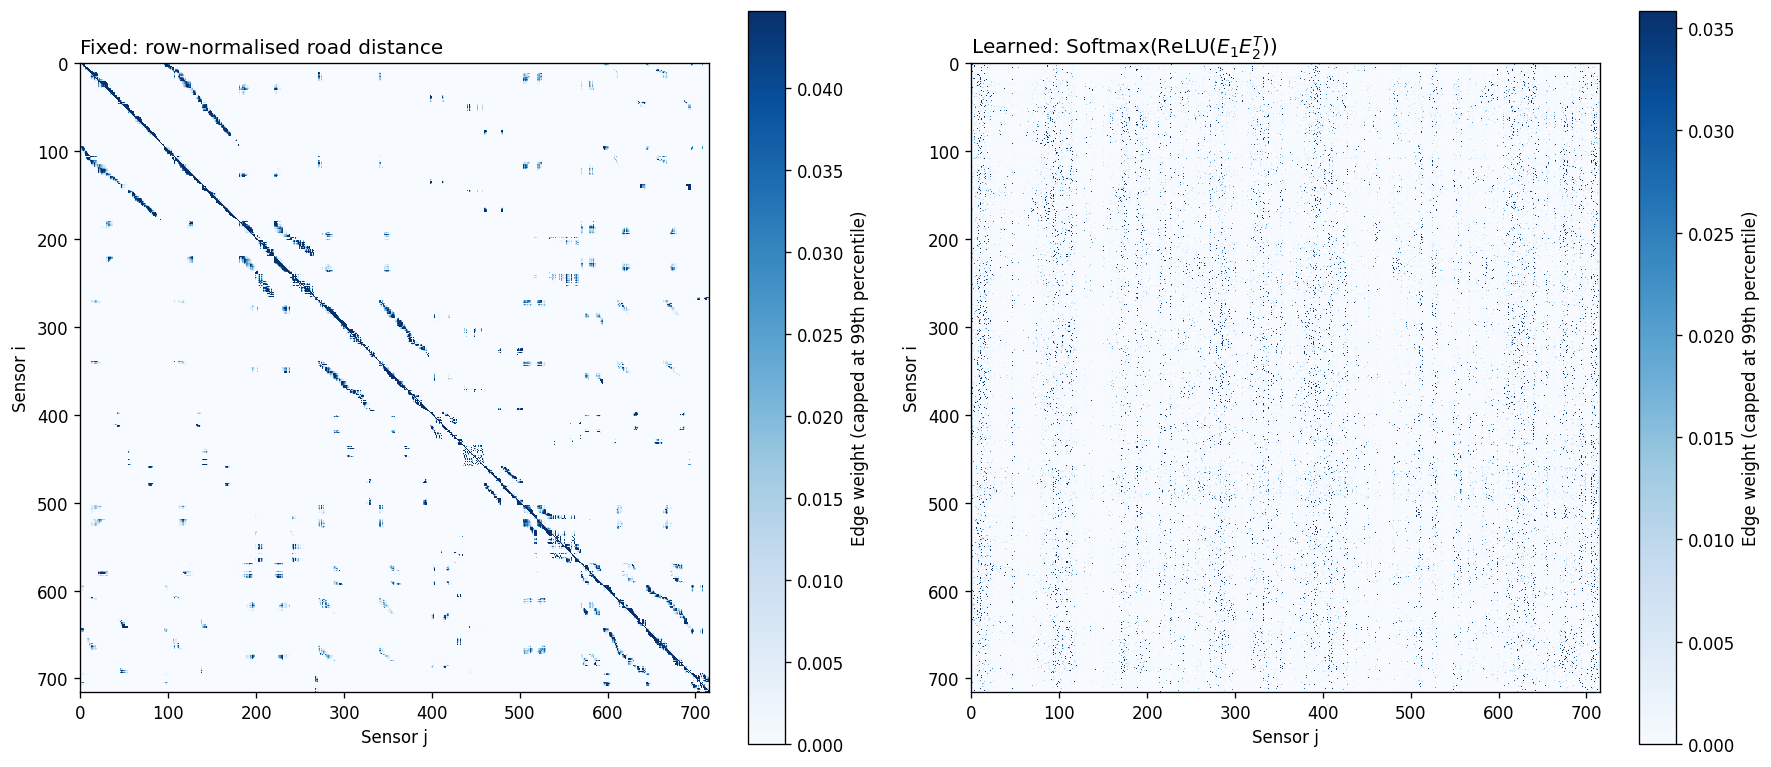

In [48]:
with torch.no_grad():
    learned_adj = adaptive_stgnn.adjacency().cpu().numpy()

# How concentrated each row of the learned graph is
sorted_rows = np.sort(learned_adj, axis=1)[:, ::-1]
strongest = sorted_rows[:, 0].mean()
top_10_share = sorted_rows[:, :10].sum(axis=1).mean()

print("Largest learned weight :", round(float(learned_adj.max()), 4))
print("Mean strongest weight per row :", round(float(strongest), 4))
print("Mean weight in the 10 strongest per row :", round(float(top_10_share), 4))
print("Uniform weight (1 / 716) :", round(1 / num_nodes, 4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), dpi=120)
graphs = [
    ("Fixed: row-normalised road distance", adj_norm),
    ("Learned: Softmax(ReLU($E_1 E_2^T$))", learned_adj),
]

for ax, (title, matrix) in zip(axes, graphs):
    # Colour scale capped at the 99th percentile so weaker edges stay visible
    top = np.quantile(matrix, 0.99)
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=top, interpolation="nearest")
    fig.colorbar(image, ax=ax, label="Edge weight (capped at 99th percentile)")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Sensor j")
    ax.set_ylabel("Sensor i")

fig.tight_layout()
plt.show()

### Q5(c) – Hybrid adjacency

#### Hybrid model

In [49]:
class HybridSTGNN(AdaptiveSTGNN):
    # A_hybrid = alpha * A_fixed + (1 - alpha) * A_adaptive, with alpha learned.
    # Both graphs have rows summing to 1, so the hybrid rows also sum to 1.
    def __init__(self, hidden, embed_dim, adj_fixed):
        super().__init__(hidden, embed_dim)
        self.adj = adj_fixed
        # alpha = sigmoid(logit) stays in [0, 1] and starts at 0.5
        self.alpha_logit = nn.Parameter(torch.zeros(()))

    def alpha(self):
        return torch.sigmoid(self.alpha_logit)

    def adjacency(self):
        adaptive = super().adjacency()
        return self.alpha() * self.adj + (1 - self.alpha()) * adaptive


torch.manual_seed(seed)
hybrid_stgnn = HybridSTGNN(hidden, embed_dim, adj_norm_t).to(device)
param_count = sum(p.numel() for p in hybrid_stgnn.parameters())
hybrid_row_sums = hybrid_stgnn.adjacency().sum(dim=1).cpu()

print("Trainable parameters :", param_count)
print("Starting alpha :", hybrid_stgnn.alpha().item())
print("Rows sum to 1 :", torch.allclose(hybrid_row_sums, torch.ones(num_nodes)))
print("Output batch shape :", tuple(hybrid_stgnn(sample).shape))

Trainable parameters : 22837
Starting alpha : 0.5
Rows sum to 1 : True
Output batch shape : (2, 4, 716, 1)


/tmp/ipykernel_13892/2010895789.py:21: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at external/rules_python++pip+torch_tpu_pypi_2_14_0_314_torch/site-packages/torch/include/ATen/core/TensorBody.h:494.)
  hybrid_row_sums = hybrid_stgnn.adjacency().sum(dim=1).cpu()
/tmp/ipykernel_13892/2010895789.py:24: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access t

#### Train hybrid model

In [50]:
# Same seed (set when the model was built) and training protocol as STGNN
run = train_model(hybrid_stgnn, "stgnn_hybrid")

val_mae, val_rmse = evaluate(hybrid_stgnn, "val")
test_mae, test_rmse = evaluate(hybrid_stgnn, "test")
results["STGNN hybrid"] = {
    "val_mae": val_mae,
    "val_rmse": val_rmse,
    "test_mae": test_mae,
    "test_rmse": test_rmse,
    "best_epoch": run["best_epoch"],
    "epochs_run": run["epoch"],
    "train_time_s": run["train_time_s"],
}

learned_alpha = hybrid_stgnn.alpha().item()
print("Learned alpha (weight on the fixed graph) :", round(learned_alpha, 4))
print("Validation MAE :", round(val_mae, 2))
print("Validation RMSE :", round(val_rmse, 2))
print("Test MAE :", round(test_mae, 2))
print("Test RMSE :", round(test_rmse, 2))

Epoch 1 train MAE : 72.01 val MAE : 57.46 time (s) : 5.4
Epoch 2 train MAE : 54.92 val MAE : 55.61 time (s) : 5.6
Epoch 3 train MAE : 52.39 val MAE : 52.95 time (s) : 5.6
Epoch 4 train MAE : 50.68 val MAE : 55.33 time (s) : 5.5
Epoch 5 train MAE : 49.49 val MAE : 50.02 time (s) : 5.6
Epoch 6 train MAE : 48.42 val MAE : 49.23 time (s) : 5.6
Epoch 7 train MAE : 48.06 val MAE : 51.05 time (s) : 5.7
Epoch 8 train MAE : 47.49 val MAE : 48.33 time (s) : 5.6
Epoch 9 train MAE : 46.95 val MAE : 48.38 time (s) : 5.6
Epoch 10 train MAE : 46.5 val MAE : 47.58 time (s) : 5.7
Epoch 11 train MAE : 46.26 val MAE : 47.66 time (s) : 5.7
Epoch 12 train MAE : 45.9 val MAE : 47.86 time (s) : 5.7
Epoch 13 train MAE : 45.69 val MAE : 47.91 time (s) : 5.4
Epoch 14 train MAE : 45.48 val MAE : 46.61 time (s) : 5.4
Epoch 15 train MAE : 45.25 val MAE : 47.5 time (s) : 5.5
Epoch 16 train MAE : 44.98 val MAE : 46.73 time (s) : 5.2
Epoch 17 train MAE : 44.87 val MAE : 45.97 time (s) : 5.8
Epoch 18 train MAE : 44.81

/tmp/ipykernel_13892/258197287.py:16: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at external/rules_python++pip+torch_tpu_pypi_2_14_0_314_torch/site-packages/torch/include/ATen/core/TensorBody.h:494.)
  learned_alpha = hybrid_stgnn.alpha().item()


#### Compare fixed, adaptive and hybrid

In [51]:
graph_models = ["STGNN", "STGNN adaptive", "STGNN hybrid"]
graph_comparison = pd.DataFrame(results).T.loc[graph_models]
graph_comparison.index = ["Fixed", "Adaptive", "Hybrid"]
display(graph_comparison.round(2))

,val_mae,val_rmse,test_mae,test_rmse,best_epoch,epochs_run,train_time_s
Fixed,51.57,82.81,60.92,95.94,66.0,76.0,382.12
Adaptive,44.15,71.20,53.47,84.00,34.0,44.0,235.50
Hybrid,41.82,67.50,51.09,80.64,94.0,100.0,563.09


#### Comparison

The learned graph beats the fixed road-distance graph: test MAE drops from 60.92 to 53.47 (12.2%) and RMSE from 95.94 to 84.00. The hybrid graph is best (test MAE 51.09, RMSE 80.64), but its learned $\alpha$ is only 0.026, so it relies almost entirely on the learned graph. No top-$k$ sparsification is used; the dense 716 × 716 graph is cheap, and the 10 strongest learned edges already hold about 70% of each row.

## Question 6 – Experimental Analysis and Interpretation

### Q6(a) – Forecasting comparison

#### Final comparison table

In [52]:
# Test-set results; all models use the same test period (April-December 2021)
final_rows = [
    ("Temporal-only", "None", "Temporal-only"),
    ("STGNN", "Fixed", "STGNN"),
    ("STGNN", "Adaptive", "STGNN adaptive"),
    ("STGNN", "Hybrid", "STGNN hybrid"),
]

table_rows = []
for model_name, adjacency, key in final_rows:
    row = {
        "Model": model_name,
        "Adjacency": adjacency,
        "MAE": results[key]["test_mae"],
        "RMSE": results[key]["test_rmse"],
        "Training time (s)": results[key]["train_time_s"],
    }
    table_rows.append(row)

final_table = pd.DataFrame(table_rows)
display(final_table.round(2))

,Model,Adjacency,MAE,RMSE,Training time (s)
0,Temporal-only,None,64.66,101.45,331.05
1,STGNN,Fixed,60.92,95.94,382.12
2,STGNN,Adaptive,53.47,84.00,235.50
3,STGNN,Hybrid,51.09,80.64,563.09


#### Predicted vs actual flow

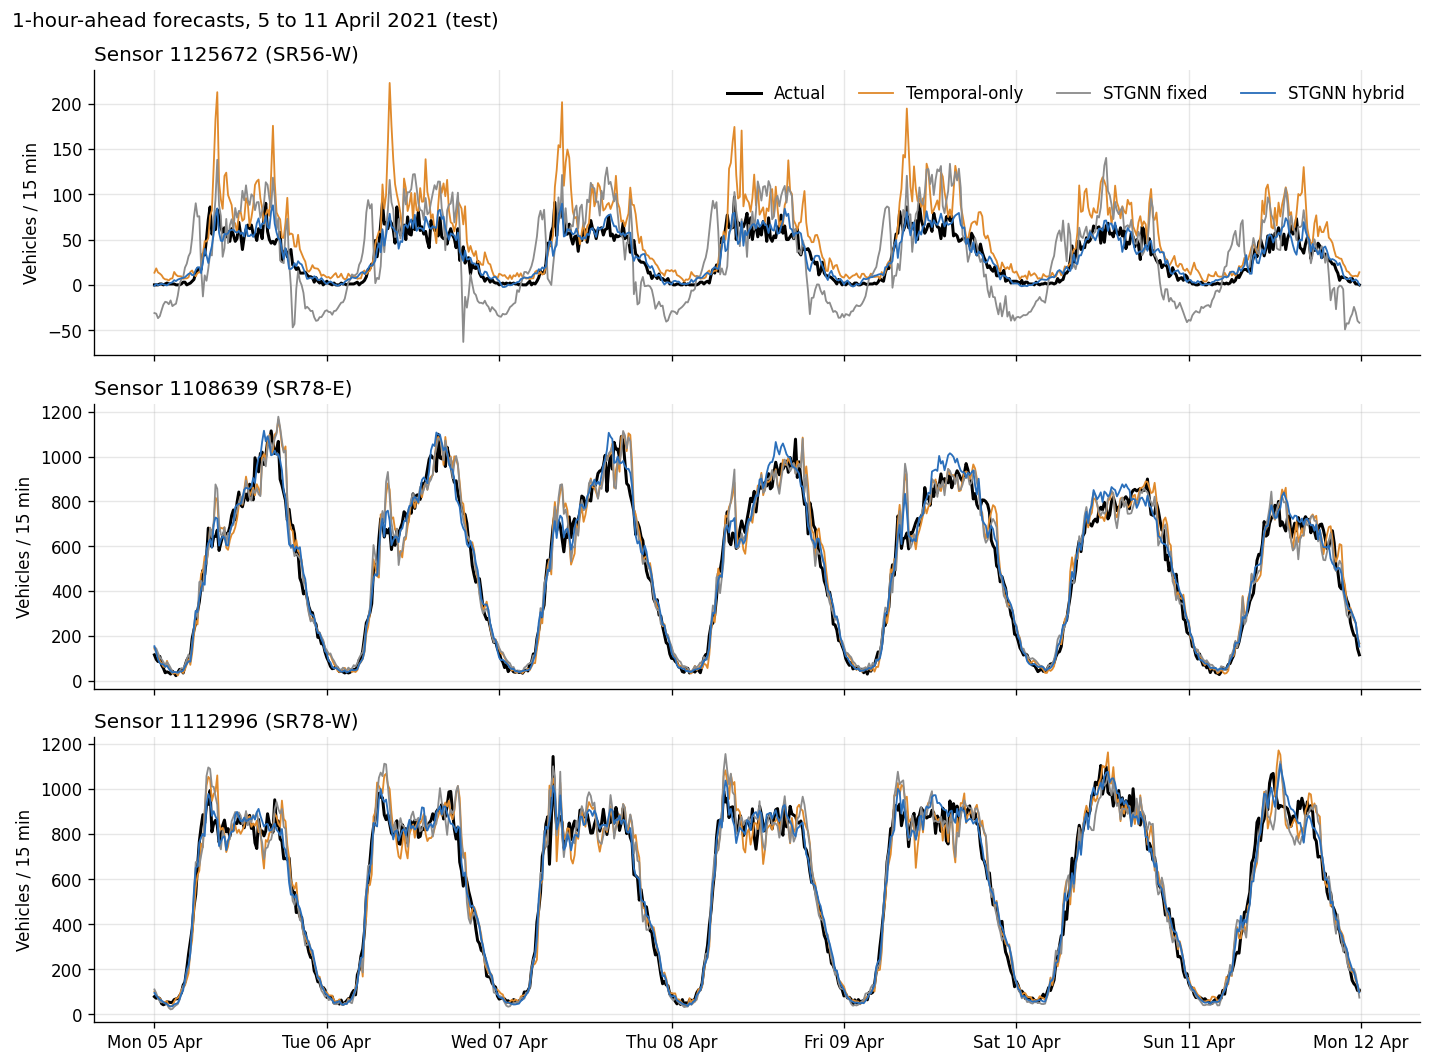

In [53]:
def predict(model, split, indices):
    # Forecasts in vehicles / 15 min, shape (windows, 4, sensors)
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(indices), batch_size):
            end = start + batch_size
            chunk = indices[start:end]
            # Padded to a full batch so the TPU always sees one shape
            padded = np.full(batch_size, chunk[-1])
            padded[: len(chunk)] = chunk
            x_batch, _, _ = get_batch(split, padded)
            pred = model(x_batch)[: len(chunk), :, :, 0]
            outputs.append(pred.cpu().numpy())
    return np.concatenate(outputs) * scale + float(flow_mean)


# One Monday-to-Sunday week from the test period, forecast 1 hour ahead
horizon = 4
test_times = flow_15min.loc["2021-04-01":"2021-12-31"].index
week_times = flow_15min.loc["2021-04-05":"2021-04-11"].index
target_positions = test_times.get_indexer(week_times)

# Window s forecasts steps s + 8 to s + 11, so its horizon-th forecast is step s + 7 + h
window_indices = target_positions - (input_steps - 1) - horizon

plot_models = {
    "Temporal-only": temporal_only,
    "STGNN fixed": stgnn,
    "STGNN hybrid": hybrid_stgnn,
}
week_preds = {}
for name, model in plot_models.items():
    week_preds[name] = predict(model, "test", window_indices)[:, horizon - 1, :]

colors = {
    "Temporal-only": "#e08a2c",
    "STGNN fixed": "#8c8c8c",
    "STGNN hybrid": "#2a6fbb",
}


def plot_sensor(ax, sensor_id):
    column = flow_15min.columns.get_loc(sensor_id)
    # Actual values before filling, so gaps show as gaps
    actual = flow_15min.loc[week_times, sensor_id]
    ax.plot(week_times, actual, color="black", linewidth=1.8, label="Actual")

    for name, pred in week_preds.items():
        forecast = pred[:, column]
        ax.plot(week_times, forecast, color=colors[name], linewidth=1.1, label=name)

    fwy = chosen.loc[sensor_id, "Fwy"]
    ax.set_title("Sensor " + sensor_id + " (" + fwy + ")", loc="left")
    ax.set_ylabel("Vehicles / 15 min")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)


# Same three sensors as the Q3(a) week plot
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, dpi=120)
for ax, sensor_id in zip(axes, chosen.index):
    plot_sensor(ax, sensor_id)

axes[0].legend(loc="upper right", ncol=4, frameon=False)
axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
fig.suptitle("1-hour-ahead forecasts, 5 to 11 April 2021 (test)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### Q6(b) – Graph structure analysis

#### Strongest learned edges vs the road graph

In [54]:
# learned_adj is the adaptive graph from Q5(b); self-weights are left out here
learned_no_self = learned_adj.copy()
np.fill_diagonal(learned_no_self, 0)
road_edge = off_diagonal > 0

# The 10 strongest learned neighbours of every sensor
top_k = 10
top_neighbours = np.argsort(-learned_no_self, axis=1)[:, :top_k]
pair_rows = np.repeat(np.arange(num_nodes), top_k)
pair_cols = top_neighbours.ravel()
top_in_road = road_edge[pair_rows, pair_cols]

# The 1000 strongest learned edges in the whole graph
strongest = np.argsort(-learned_no_self, axis=None)[:1000]
strong_rows, strong_cols = np.unravel_index(strongest, learned_no_self.shape)
strong_in_road = road_edge[strong_rows, strong_cols]

chance_pct = 100 * road_edge.mean()
top_pct = 100 * top_in_road.mean()
strong_pct = 100 * strong_in_road.mean()
road_weight = (learned_no_self * road_edge).sum(axis=1).mean()
self_weight = np.diag(learned_adj).mean()

print("Road edges among all sensor pairs, chance level (%) :", round(chance_pct, 2))
print("Top-10 learned neighbours that are road edges (%) :", round(top_pct, 2))
print("1000 strongest learned edges that are road edges (%) :", round(strong_pct, 2))
print("Learned weight on road edges, mean per row :", round(float(road_weight), 4))
print("Learned weight on the sensor itself, mean :", round(float(self_weight), 4))
print("Top-10 learned edges not in the road graph :", (~top_in_road).sum())
print("Top-10 learned edges in total :", len(top_in_road))

Road edges among all sensor pairs, chance level (%) : 3.38
Top-10 learned neighbours that are road edges (%) : 5.07
1000 strongest learned edges that are road edges (%) : 5.9
Learned weight on road edges, mean per row : 0.047
Learned weight on the sensor itself, mean : 0.0017
Top-10 learned edges not in the road graph : 6797
Top-10 learned edges in total : 7160


#### Distance between connected sensors

Road-graph edges
  median distance (km) : 2.4
  within 5 km (%) : 100.0
  further than 20 km (%) : 0.0
Top-10 learned edges
  median distance (km) : 21.4
  within 5 km (%) : 8.4
  further than 20 km (%) : 53.0
Top-10 learned edges not in road graph
  median distance (km) : 22.5
  within 5 km (%) : 3.5
  further than 20 km (%) : 55.9
All sensor pairs
  median distance (km) : 23.0
  within 5 km (%) : 5.9
  further than 20 km (%) : 57.3


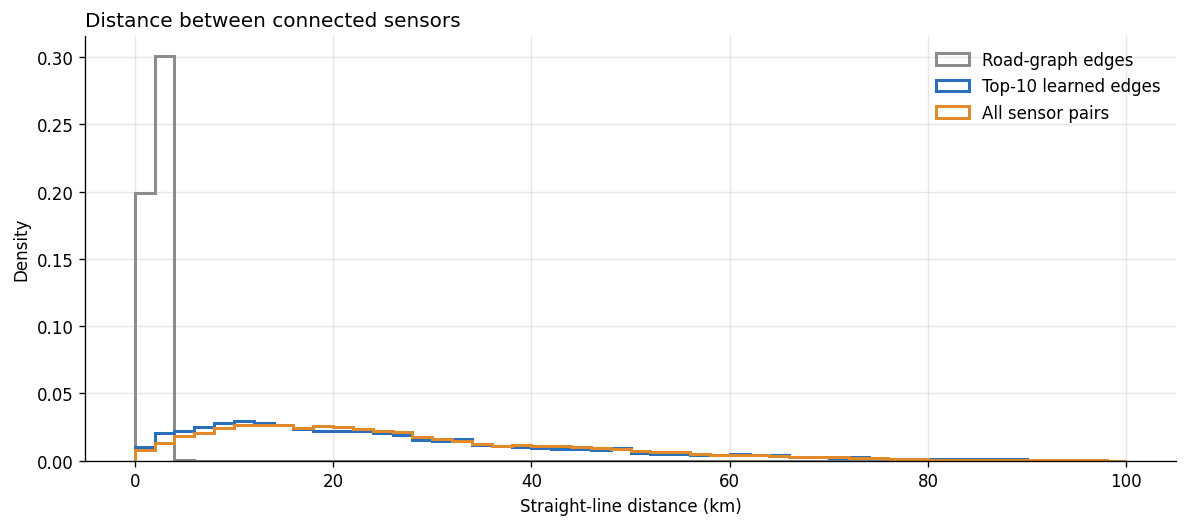

In [55]:
def distance_matrix_km(lat_deg, lng_deg):
    # Straight-line (haversine) distance between every pair of sensors
    lat = np.radians(lat_deg)
    lng = np.radians(lng_deg)
    dlat = lat[:, None] - lat[None, :]
    dlng = lng[:, None] - lng[None, :]
    cos_term = np.cos(lat[:, None]) * np.cos(lat[None, :])
    a = np.sin(dlat / 2) ** 2 + cos_term * np.sin(dlng / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


# sd_meta rows are in the same order as the flow columns and the adjacency
distance_km = distance_matrix_km(sd_meta["Lat"].to_numpy(), sd_meta["Lng"].to_numpy())
not_self = ~np.eye(num_nodes, dtype=bool)
learned_km = distance_km[pair_rows, pair_cols]

distance_groups = {
    "Road-graph edges": distance_km[road_edge],
    "Top-10 learned edges": learned_km,
    "Top-10 learned edges not in road graph": learned_km[~top_in_road],
    "All sensor pairs": distance_km[not_self],
}


def print_distances(name, distances):
    print(name)
    print("  median distance (km) :", round(float(np.median(distances)), 1))
    print("  within 5 km (%) :", round(100 * float(np.mean(distances <= 5)), 1))
    print("  further than 20 km (%) :", round(100 * float(np.mean(distances > 20)), 1))


for name, distances in distance_groups.items():
    print_distances(name, distances)

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
bins = np.arange(0, 102, 2)
hist_groups = ["Road-graph edges", "Top-10 learned edges", "All sensor pairs"]
hist_colors = ["#8c8c8c", "#2a6fbb", "#e08a2c"]

for name, color in zip(hist_groups, hist_colors):
    ax.hist(
        distance_groups[name],
        bins=bins,
        density=True,
        histtype="step",
        linewidth=1.8,
        color=color,
        label=name,
    )

ax.set_title("Distance between connected sensors", loc="left")
ax.set_xlabel("Straight-line distance (km)")
ax.set_ylabel("Density")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

#### Traffic similarity of connected sensors

In [56]:
# Correlation of training-period (2020) flow between every pair of sensors.
# Sensors that never report are constant, so their correlations are NaN and skipped.
with np.errstate(invalid="ignore", divide="ignore"):
    train_corr = np.corrcoef(split_flow["train"].T)
learned_corr = train_corr[pair_rows, pair_cols]

corr_groups = {
    "Road-graph edges": train_corr[road_edge],
    "Top-10 learned edges": learned_corr,
    "Top-10 learned edges not in road graph": learned_corr[~top_in_road],
    "All sensor pairs": train_corr[not_self],
}

for name, corr in corr_groups.items():
    print(name, "mean flow correlation :", round(float(np.nanmean(corr)), 3))

Road-graph edges mean flow correlation : 0.837
Top-10 learned edges mean flow correlation : 0.851
Top-10 learned edges not in road graph mean flow correlation : 0.851
All sensor pairs mean flow correlation : 0.824


#### Sensors that receive the most learned weight

In [ ]:
incoming = learned_no_self.sum(axis=0)
no_train_data = ~split_mask["train"].any(axis=0)

hubs = pd.DataFrame(
    {"incoming_weight": incoming, "no_training_data": no_train_data},
    index=flow_15min.columns,
)
hubs = hubs.join(sensor_summary[["Fwy", "nan_pct"]])

top_hubs = hubs.sort_values("incoming_weight", ascending=False).head(10)
hub_share = 100 * top_hubs["incoming_weight"].sum() / incoming.sum()
print("Mean incoming weight per sensor :", round(float(incoming.mean()), 3))
print("Weight held by the 10 strongest hubs (%) :", round(float(hub_share), 1))
print("Sensors with no training data :", no_train_data.sum())
print("Of these, among the 10 strongest hubs :", top_hubs["no_training_data"].sum())
display(top_hubs.round(3))

Mean incoming weight per sensor : 0.998
Weight held by the 10 strongest hubs (%) : 13.2
Sensors with no training data : 19
Of these, among the 10 strongest hubs : 6


,incoming_weight,no_training_data,Fwy,nan_pct
1126526,14.768,False,I905-W,0.01
1111551,12.742,True,I8-E,100.00
1118458,11.164,True,I5-N,100.00
1111552,9.898,True,I8-W,100.00
1115348,9.561,True,I5-S,100.00
1123087,7.971,True,I5-N,100.00
1123069,7.451,True,I805-S,100.00
1125912,7.297,False,I805-N,88.38
1114190,6.704,False,I5-N,0.01
1126722,6.654,False,I15-N,0.01


#### Discussion

1. **Strongest learned connections in the road graph?** Mostly not: 5.1% of each sensor's 10 strongest learned neighbours are road edges, against 3.4% for a random pair.
2. **Between nearby sensors?** No. Learned edges have a median distance of 21.4 km, close to the 23.0 km of random pairs; road edges are all within 5 km.
3. **Dependencies absent from the physical graph?** Yes: 94.9% of the top learned edges are not road edges, and they link sensors with slightly more similar 2020 traffic (correlation 0.851 vs 0.837 for road edges). But 6 of the 10 sensors that receive the most weight have no training data, so their constant input acts as a bias, not a traffic dependency.
4. **Better or worse than a fixed graph?** Better when the loss finds useful links that distance misses and drops unhelpful road neighbours such as the opposite direction; worse when the embeddings overfit or pick up artefacts, since they ignore the road structure that congestion actually travels along.

### Q6(c) – Critical discussion

- **Does lower error mean the learned graph is the road network?** No. The adaptive graph lowers test MAE by 12.2%, yet its edges are no closer than random pairs and barely overlap the road graph. It is trained only to reduce the loss, so it uses similar daily patterns and even constant inputs.
- **Why can a hybrid graph win?** The fixed graph gives a reliable local prior from the first epoch and the learned graph adds long-range links; a learned $\alpha$ picks the mix. Here $\alpha$ = 0.026 and the hybrid was 4.5% better than adaptive, though it also trained longer (100 vs 44 epochs).
- **Limits of a static graph?** One $\hat{A}$ uses the same weights all day, but the useful neighbours change: morning and evening commutes load opposite directions, congestion spreads upstream only while a road is congested, and nights, weekends and incidents behave differently. A time-dependent graph could follow these changes.